# PyTorch — L’essentiel du framework

**Objectifs :**
- comprendre les `Tensor` ;
- utiliser `Autograd` ;
- construire un modèle avec `nn.Module` ;
- définir un `Loss` et un `Optimizer` ;
- écrire une boucle d’apprentissage ;
- distinguer `train()` et `eval()` ;
- utiliser `Dataset` / `DataLoader` ;
- entraîner un exemple de régression et un exemple de classification ;
- sauvegarder et recharger un modèle.

## 0. Préparation

Le notebook fonctionne sur CPU. S’il existe un GPU CUDA, PyTorch pourra l’utiliser automatiquement.

In [68]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

PyTorch version: 2.14.1+cpu
CUDA disponible: False


## 1. Workflow général

Le cycle de base est :

**Données → Tensors → Modèle → Prédictions → Loss → Backward → Optimizer → Mise à jour**

In [69]:
# Pseudo-code de la logique générale
# y_pred = model(X)
# loss = criterion(y_pred, y)
# optimizer.zero_grad()
# loss.backward()
# optimizer.step()

## 2. Les Tensors

Un `Tensor` est la structure de données fondamentale de PyTorch.

In [70]:
scalar = torch.tensor(3.0)
vector = torch.tensor([1.0, 2.0, 3.0])
matrix = torch.tensor([[1.0, 2.0], [3.0, 4.0]])

print("scalar:", scalar, "shape =", scalar.shape)
print("vector:", vector, "shape =", vector.shape)
print("matrix:", matrix, "shape =", matrix.shape)
print("dtype:", matrix.dtype)
print("ndim:", matrix.ndim)

scalar: tensor(3.) shape = torch.Size([])
vector: tensor([1., 2., 3.]) shape = torch.Size([3])
matrix: tensor([[1., 2.],
        [3., 4.]]) shape = torch.Size([2, 2])
dtype: torch.float32
ndim: 2


### Manipulation de Tensors

In [71]:
x = torch.arange(12)
print("x =", x)

x2 = x.reshape(3, 4)
print("reshape(3,4):", x2)

print("Colonne 1:", x2[:, 1])
print("Ligne 0:", x2[0, :])

A = torch.tensor([[1., 2.], [3., 4.]])
B = torch.tensor([[2., 0.], [1., 2.]])
print("A @ B =", A @ B)

print("mean(A) =", A.mean())
print("sum(A) =", A.sum())

x = tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
reshape(3,4): tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
Colonne 1: tensor([1, 5, 9])
Ligne 0: tensor([0, 1, 2, 3])
A @ B = tensor([[ 4.,  4.],
        [10.,  8.]])
mean(A) = tensor(2.5000)
sum(A) = tensor(10.)


## 3. CPU, GPU et `device`

In [72]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilisé:", device)

x = torch.tensor([1.0, 2.0, 3.0]).to(device)
print("x.device =", x.device)

Device utilisé: cpu
x.device = cpu


## 4. Autograd

`Autograd` calcule automatiquement les dérivées à partir du graphe de calcul.

In [73]:
x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2

loss.backward()

print("y =", y.item())
print("loss =", loss.item())
print("dLoss/dw =", w.grad.item())
print("dLoss/db =", b.grad.item())

y = 7.0
loss = 9.0
dLoss/dw = -12.0
dLoss/db = -6.0


In [74]:
import torch

x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2

dw, db = torch.autograd.grad(loss, (w, b))

print("y =", y.item())
print("loss =", loss.item())
print("dLoss/dw =", dw.item())
print("dLoss/db =", db.item())

y = 7.0
loss = 9.0
dLoss/dw = -12.0
dLoss/db = -6.0


### Vérification analytique

Ici :

\[
y = wx+b
\]

et

\[
L=(y-10)^2
\]

Donc :

\[

rac{\partial L}{\partial w}=2(y-10)x
\]

\[

rac{\partial L}{\partial b}=2(y-10)
\]

In [75]:
y_val = (3.0 * 2.0 + 1.0)
dL_dw = 2 * (y_val - 10) * 2.0
dL_db = 2 * (y_val - 10)
print(dL_dw, dL_db)

-12.0 -6.0


## 5. Un neurone avec `nn.Linear`

Un neurone linéaire calcule essentiellement :

\[
z = \sum_i w_i x_i + b
\]

In [76]:
model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)

print("Sortie:", y)
print("Poids:", model.weight)
print("Biais:", model.bias)

Sortie: tensor([[-0.0258]], grad_fn=<AddmmBackward0>)
Poids: Parameter containing:
tensor([[-0.4835,  0.2336,  0.0739]], requires_grad=True)
Biais: Parameter containing:
tensor([-0.2312], requires_grad=True)


In [77]:
import torch
import torch.nn as nn
from torchviz import make_dot

model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)

print("Sortie:", y)
print("Poids:", model.weight)
print("Biais:", model.bias)

dot = make_dot(y, params=dict(model.named_parameters()))

Sortie: tensor([[0.1709]], grad_fn=<AddmmBackward0>)
Poids: Parameter containing:
tensor([[-0.1952,  0.1510, -0.1044]], requires_grad=True)
Biais: Parameter containing:
tensor([0.3773], requires_grad=True)


## 6. Construire un réseau avec `nn.Module`

In [78]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3)
        )

    def forward(self, x):
        return self.net(x)

model = MLP()
print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
)


In [79]:
model = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3)
        )
print(model)

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=3, bias=True)
)


## 7. Fonctions d’activation

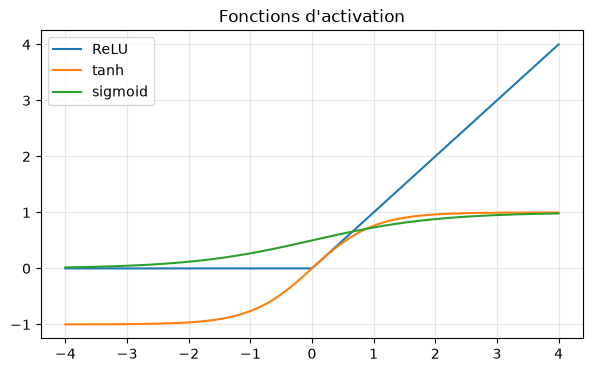

In [80]:
x = torch.linspace(-4, 4, 200)
relu = torch.relu(x)
tanh = torch.tanh(x)
sigmoid = torch.sigmoid(x)

plt.figure(figsize=(7,4))
plt.plot(x.numpy(), relu.numpy(), label='ReLU')
plt.plot(x.numpy(), tanh.numpy(), label='tanh')
plt.plot(x.numpy(), sigmoid.numpy(), label='sigmoid')
plt.grid(True, alpha=0.3)
plt.legend()
plt.title("Fonctions d'activation")
plt.show()

## 8. Forward propagation

L’appel `model(X)` déclenche automatiquement `model.forward(X)`.

In [81]:
X = torch.randn(5, 4)
# L’appel model(X) déclenche automatiquement model.forward(X)
predicted = model(X)
print("Shape entrée :", X.shape)
print("Shape sortie :", predicted.shape)

Shape entrée : torch.Size([5, 4])
Shape sortie : torch.Size([5, 3])


## 9. Fonctions de coût

Cas principaux :
- régression : `nn.MSELoss()` ;
- classification multi-classe : `nn.CrossEntropyLoss()` ;
- classification binaire : `nn.BCEWithLogitsLoss()`.

In [82]:
# Régression
criterion_reg = nn.MSELoss()
y_pred = torch.tensor([[2.0], [4.0]])
y_true = torch.tensor([[3.0], [5.0]])
print("MSE =", criterion_reg(y_pred, y_true).item())

# Classification multi-classe
criterion_cls = nn.CrossEntropyLoss()
pred = torch.tensor([[2.0, 1.0, 0.5], [0.2, 0.1, 2.0]])
y = torch.tensor([0, 2])
print("CrossEntropy =", criterion_cls(pred, y).item())

MSE = 1.0
CrossEntropy = 0.36905235052108765


## 10. Optimizers

L’optimiseur utilise les gradients pour mettre à jour les paramètres.

In [83]:
simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)


## 11. La boucle d’apprentissage

C’est le cœur de PyTorch.

In [84]:
X = torch.randn(8, 1)
y = 2 * X + 1
simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
criterion = nn.MSELoss()
epochs = 500
# Exemple générique
for epoch in range(epochs):
    simple_model.train()
    y_pred = simple_model(X)
    loss = criterion(y_pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 100 ==0 : 
        print(f"epoch={epoch} loss={loss.item():.4f}")

epoch=0 loss=6.0251
epoch=100 loss=1.7460
epoch=200 loss=0.3544
epoch=300 loss=0.0462
epoch=400 loss=0.0037


## 12. `train()` vs `eval()`

`model.train()` et `model.eval()` influencent notamment le comportement de `Dropout` et `BatchNorm`.

`eval()` ne désactive pas le calcul des gradients. Pour l’inférence, on utilise généralement `torch.inference_mode()`.

In [85]:
class DropoutDemo(nn.Module):
    def __init__(self):
        super().__init__()
        self.dropout = nn.Dropout(p=0.5)

    def forward(self, x):
        return self.dropout(x)

m = DropoutDemo()
x = torch.ones(10)

m.train()
print("train() :", m(x))

m.eval()
with torch.inference_mode():
    print("eval()  :", m(x))

train() : tensor([0., 0., 0., 0., 2., 2., 2., 2., 2., 2.])
eval()  : tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


## 13. Dataset et DataLoader

In [86]:
X = torch.randn(100, 3)
y = torch.randn(100, 1)

dataset = TensorDataset(X, y)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

for X_batch, y_batch in loader:
    print("Batch X:", X_batch.shape, "Batch y:", y_batch.shape)
    break

Batch X: torch.Size([16, 3]) Batch y: torch.Size([16, 1])


# Partie pratique 1 — Régression linéaire

Nous générons des données proches de :

\[
y = 3x + 2 + bruit
\]

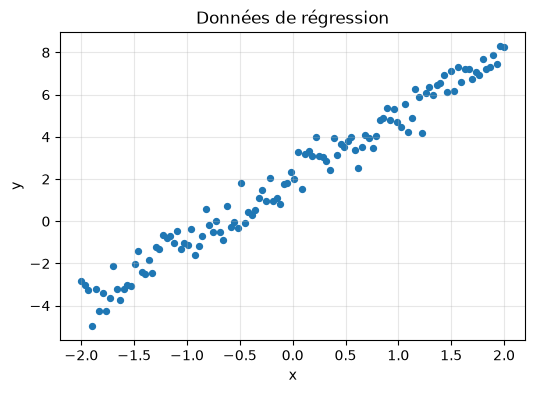

In [87]:
torch.manual_seed(42)

X = torch.linspace(-2, 2, 120).unsqueeze(1)
noise = 0.6 * torch.randn_like(X)
y = 3 * X + 2 + noise

plt.figure(figsize=(6,4))
plt.scatter(X.numpy(), y.numpy(), s=18)
plt.title("Données de régression")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.show()

## 14. Modèle, loss et optimizer

In [88]:
model_reg = nn.Linear(1, 1)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_reg.parameters(), lr=0.05)

## 15. Entraînement de la régression

In [89]:
losses = []

for epoch in range(300):
    model_reg.train()

    y_pred = model_reg(X)
    loss = criterion(y_pred, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

print("Dernier loss:", losses[-1])
print("w appris:", model_reg.weight.item())
print("b appris:", model_reg.bias.item())

Dernier loss: 0.3438417613506317
w appris: 2.9894580841064453
b appris: 2.030014991760254


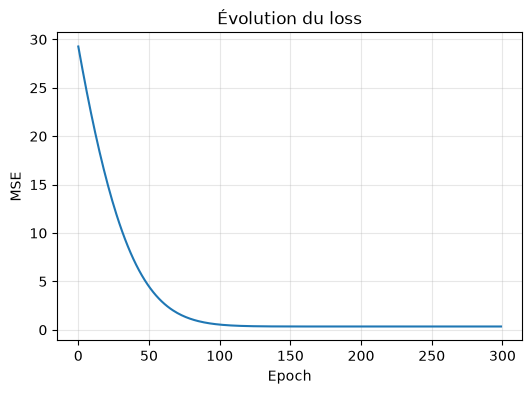

In [90]:
plt.figure(figsize=(6,4))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Évolution du loss")
plt.grid(True, alpha=0.3)
plt.show()

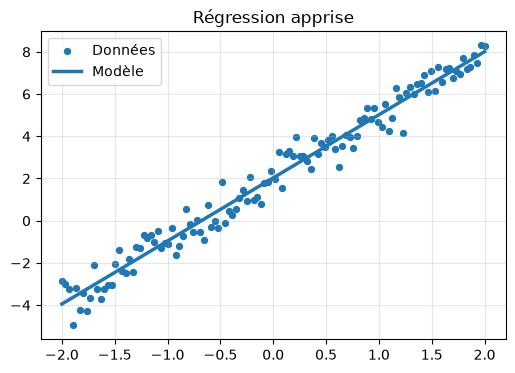

In [91]:
model_reg.eval()
with torch.inference_mode():
    y_hat = model_reg(X)

plt.figure(figsize=(6,4))
plt.scatter(X.numpy(), y.numpy(), s=18, label="Données")
plt.plot(X.numpy(), y_hat.numpy(), linewidth=2.5, label="Modèle")
plt.legend()
plt.title("Régression apprise")
plt.grid(True, alpha=0.3)
plt.show()

In [92]:
from torcheval.metrics import R2Score
metric = R2Score()
metric.update(y_hat,y)
r2=metric.compute()
print(f"R2 Score = {r2:.3f}")

R2 Score = 0.972


# Partie pratique 2 — Classification

Créons deux classes de points en 2D.

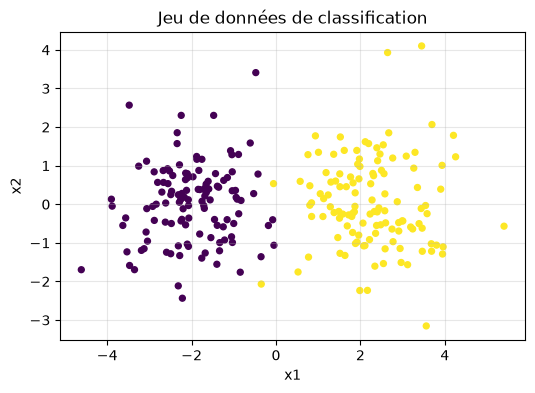

In [93]:
torch.manual_seed(0)

n = 120
class0 = torch.randn(n, 2) + torch.tensor([-2.0, 0.0])
class1 = torch.randn(n, 2) + torch.tensor([ 2.0, 0.0])

X_cls = torch.cat([class0, class1], dim=0)
y_cls = torch.cat([
    torch.zeros(n, dtype=torch.long),
    torch.ones(n, dtype=torch.long)
])

plt.figure(figsize=(6,4))
plt.scatter(X_cls[:,0], X_cls[:,1], c=y_cls, s=18)
plt.title("Jeu de données de classification")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(True, alpha=0.3)
plt.show()

## 16. Modèle de classification

In [94]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 2)
        )

    def forward(self, x):
        return self.net(x)

model_cls = Classifier()
criterion_cls = nn.CrossEntropyLoss()
optimizer_cls = torch.optim.Adam(model_cls.parameters(), lr=0.01)

## 17. Entraînement de la classification

In [95]:
losses_cls = []

for epoch in range(250):
    model_cls.train()

    logits = model_cls(X_cls)
    loss = criterion_cls(logits, y_cls)

    optimizer_cls.zero_grad()
    loss.backward()
    optimizer_cls.step()

    losses_cls.append(loss.item())

print("Dernier loss:", losses_cls[-1])

Dernier loss: 0.0006943687913008034


In [96]:
model_cls.eval()
with torch.inference_mode():
    logits = model_cls(X_cls)
    pred = logits.argmax(dim=1)
    accuracy = (pred == y_cls).float().mean()

print(f"Accuracy = {accuracy.item()*100:.2f}%")

Accuracy = 100.00%


Accuracy = 1.0000, recall= 1.0000, precision=1.0000, f1score=1.0000
tensor([[120,   0],
        [  0, 120]])


(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='Predicted class', ylabel='True class'>)

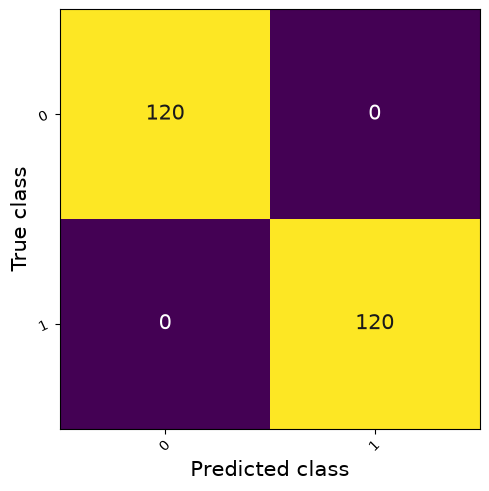

In [97]:
from torcheval.metrics import BinaryAccuracy, BinaryRecall, BinaryPrecision, BinaryPrecision, BinaryF1Score
from torchmetrics.classification import MulticlassConfusionMatrix, BinaryConfusionMatrix
accuracy_metric = BinaryAccuracy()
accuracy_metric.update(y_cls,pred)
accuracy_value = accuracy_metric.compute()

recall_metric = BinaryRecall()
recall_metric.update(y_cls, pred)
recall_value = recall_metric.compute()

precision_metric = BinaryPrecision()
precision_metric.update(y_cls,pred)
precision_value = precision_metric.compute()

f1_score_metric = BinaryF1Score()
f1_score_metric.update(y_cls, pred)
f1_score_value = f1_score_metric.compute()
print(f"Accuracy = {accuracy_value:.4f}, recall= {recall_value:.4f}, precision={precision_value:.4f}, f1score={f1_score_value:.4f}")

metric = BinaryConfusionMatrix()
confusion_matrix = metric(pred, y_cls)
print(confusion_matrix)
metric.plot()

## Visualisation de la frontière de décision

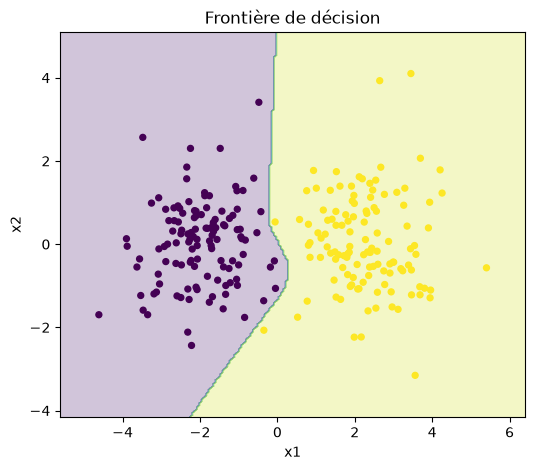

In [98]:
x1_min, x1_max = X_cls[:,0].min()-1, X_cls[:,0].max()+1
x2_min, x2_max = X_cls[:,1].min()-1, X_cls[:,1].max()+1

xx1, xx2 = torch.meshgrid(
    torch.linspace(x1_min, x1_max, 200),
    torch.linspace(x2_min, x2_max, 200),
    indexing='ij'
)

grid = torch.stack([xx1.reshape(-1), xx2.reshape(-1)], dim=1)

model_cls.eval()
with torch.inference_mode():
    zz = model_cls(grid).argmax(dim=1).reshape(xx1.shape)

plt.figure(figsize=(6,5))
plt.contourf(xx1.numpy(), xx2.numpy(), zz.numpy(), alpha=0.25)
plt.scatter(X_cls[:,0], X_cls[:,1], c=y_cls, s=18)
plt.title("Frontière de décision")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

## 18. Sauvegarder et recharger un modèle

In [99]:
path = "classifier_state_dict.pt"
torch.save(model_cls.state_dict(), path)
print("Modèle sauvegardé dans", path)

new_model = Classifier()
new_model.load_state_dict(torch.load(path, weights_only=True))
new_model.eval()

with torch.inference_mode():
    pred_new = new_model(X_cls).argmax(dim=1)

print("Prédictions identiques:", torch.equal(pred, pred_new))

Modèle sauvegardé dans classifier_state_dict.pt
Prédictions identiques: True


# Synthèse

Les briques essentielles de PyTorch sont maintenant en place :

1. `Tensor`
2. `nn.Module`
3. `forward()`
4. fonction de coût
5. `optimizer.zero_grad()`
6. `loss.backward()`
7. `optimizer.step()`
8. `train()` / `eval()`
9. `Dataset` / `DataLoader`
10. sauvegarde avec `state_dict()`

Cette mécanique reste pratiquement la même pour des modèles plus avancés : CNN, Transformers, modèles génératifs ou PINNs.

# Exercices

### Exercice 1 : Régression

Prédire le salaire selon l’ancienneté et le niveau d’expertise

Objectif:

Construire un modèle de régression linéaire multiple pour prédire le salaire mensuel à partir de deux variables :
- Ancienneté : nombre d’années d’expérience.
- Niveau d’expertise : note de 1 à 5.
Le modèle doit apprendre la relation :

Salaire = w_1 * Ancienneté + w_2 * Expertise + b 

Les salaires sont exprimés en dirhams (DH). Les données sont fictives et servent uniquement à l’apprentissage.

1. *Générer les données*

Pour cet exercice, on suppose que les salaires suivent approximativement la règle : Salaire = 4000 + 600 * Ancienneté + 1500 * Expertise} + Bruit
Le bruit représente les variations individuelles non expliquées par les deux variables.

In [100]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Nombre de salariés
n = 300

# Ancienneté : de 0 à 20 ans
anciennete = torch.randint(0, 21, (n, 1)).float()

# Expertise : de 1 à 5
expertise = torch.randint(1, 6, (n, 1)).float()

# Variations aléatoires des salaires
bruit = torch.randn(n, 1) * 500

# Salaire mensuel en DH
salaires = (
    4000
    + 600 * anciennete
    + 1500 * expertise
    + bruit
)

# Matrice des entrées : dimensions (300, 2)
X = torch.cat([anciennete, expertise], dim=1)

# Sortie : dimensions (300, 1)
y = salaires

for i in range(5):
    print(
        f"Ancienneté : {X[i, 0].item():.0f} ans | "
        f"Expertise : {X[i, 1].item():.0f}/5 | "
        f"Salaire : {y[i, 0].item():.2f} DH"
    )

Ancienneté : 15 ans | Expertise : 2/5 | Salaire : 16262.90 DH
Ancienneté : 2 ans | Expertise : 3/5 | Salaire : 10541.39 DH
Ancienneté : 4 ans | Expertise : 3/5 | Salaire : 10948.37 DH
Ancienneté : 19 ans | Expertise : 3/5 | Salaire : 20028.54 DH
Ancienneté : 18 ans | Expertise : 2/5 | Salaire : 18036.38 DH


**Travail demandé**

- Affichez les dimensions de X et de y.
- Calculez le salaire moyen.
- Tracez un nuage de points représentant le salaire selon l’ancienneté, avec une couleur différente selon l’expertise.


2. *Séparer et préparer les données*
Utilisez 80 % des données pour l’entraînement et 20 % pour le test.

Pour faciliter l’apprentissage :

standardisez les entrées à partir des statistiques du jeu d’entraînement ;
exprimez les salaires en milliers de DH.

In [101]:
indices = torch.randperm(n)
limite = int(0.8 * n)

train_indices = indices[:limite]
test_indices = indices[limite:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices] / 1000
y_test = y[test_indices] / 1000

# Statistiques calculées uniquement sur le jeu d'entraînement
moyenne = X_train.mean(dim=0, keepdim=True)
ecart_type = X_train.std(dim=0, keepdim=True)

X_train_norm = (X_train - moyenne) / ecart_type
X_test_norm = (X_test - moyenne) / ecart_type

Affichez les dimensions de X et de y.

In [102]:
# Dimensions du jeu complet
print("X shape :", X.shape)   # (300, 2) : 300 salariés, 2 variables
print("y shape :", y.shape)   # (300, 1) : 1 salaire par salarié

# Dimensions après séparation 80 / 20
print("X_train_norm shape:", X_train_norm.shape)
print("X_test_norm shape:", X_test_norm.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X shape : torch.Size([300, 2])
y shape : torch.Size([300, 1])
X_train_norm shape: torch.Size([240, 2])
X_test_norm shape: torch.Size([60, 2])
y_train shape: torch.Size([240, 1])
y_test shape: torch.Size([60, 1])


- Calculez le salaire moyen.


In [103]:
print(f"Salaire moyen (jeu complet)       : {y.mean().item():.2f} DH")
print(f"Salaire moyen (jeu d'entraînement): {y_train.mean().item() * 1000:.2f} DH")

Salaire moyen (jeu complet)       : 15010.55 DH
Salaire moyen (jeu d'entraînement): 15037.57 DH


- Tracez un nuage de points représentant le salaire selon l’ancienneté, avec une couleur différente selon l’expertise.

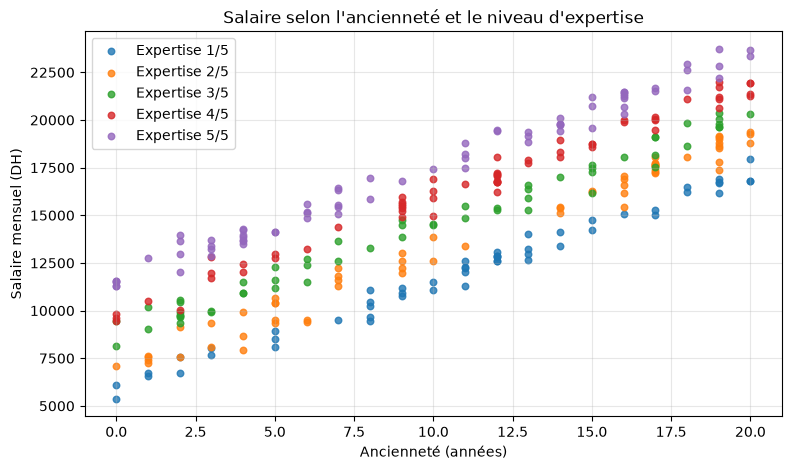

In [104]:
# Nuage de points : salaire selon l'ancienneté, une couleur par niveau d'expertise
plt.figure(figsize=(9, 5))
for niveau in range(1, 6):
    masque = X[:, 1] == niveau
    plt.scatter(
        X[masque, 0], y[masque, 0],
        s=22, alpha=0.8, label=f"Expertise {niveau}/5"
    )
plt.xlabel("Ancienneté (années)")
plt.ylabel("Salaire mensuel (DH)")
plt.title("Salaire selon l'ancienneté et le niveau d'expertise")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

3. *Construire et entraîner le modèle*

In [105]:
# Deux variables d'entrée et une sortie
model = nn.Linear(2, 1)

# Erreur quadratique moyenne
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.05
)

historique = []

model.train()

for epoch in range(1000):
    # 1. Réinitialiser les gradients
    optimizer.zero_grad()

    # 2. Prédire les salaires
    predictions = model(X_train_norm)

    # 3. Calculer la perte
    loss = criterion(predictions, y_train)

    # 4. Calculer les gradients
    loss.backward()

    # 5. Mettre à jour les paramètres
    optimizer.step()

    historique.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Époque {epoch + 1} | "
            f"Perte : {loss.item():.4f}"
        )

Époque 10 | Perte : 219.7329
Époque 20 | Perte : 202.8600
Époque 30 | Perte : 187.4826
Époque 40 | Perte : 173.4169
Époque 50 | Perte : 160.4622
Époque 60 | Perte : 148.4752
Époque 70 | Perte : 137.3359
Époque 80 | Perte : 126.9364
Époque 90 | Perte : 117.1974
Époque 100 | Perte : 108.0659
Époque 110 | Perte : 99.5053
Époque 120 | Perte : 91.4872
Époque 130 | Perte : 83.9876
Époque 140 | Perte : 76.9837
Époque 150 | Perte : 70.4532
Époque 160 | Perte : 64.3741
Époque 170 | Perte : 58.7246
Époque 180 | Perte : 53.4834
Époque 190 | Perte : 48.6294
Époque 200 | Perte : 44.1420
Époque 210 | Perte : 40.0010
Époque 220 | Perte : 36.1866
Époque 230 | Perte : 32.6797
Époque 240 | Perte : 29.4616
Époque 250 | Perte : 26.5142
Époque 260 | Perte : 23.8202
Époque 270 | Perte : 21.3624
Époque 280 | Perte : 19.1249
Époque 290 | Perte : 17.0919
Époque 300 | Perte : 15.2486
Époque 310 | Perte : 13.5808
Époque 320 | Perte : 12.0749
Époque 330 | Perte : 10.7181
Époque 340 | Perte : 9.4983
Époque 350 | P

Travail demandé :

- Complétez le modèle et la boucle d’entraînement.
- Tracez l’évolution de la perte :


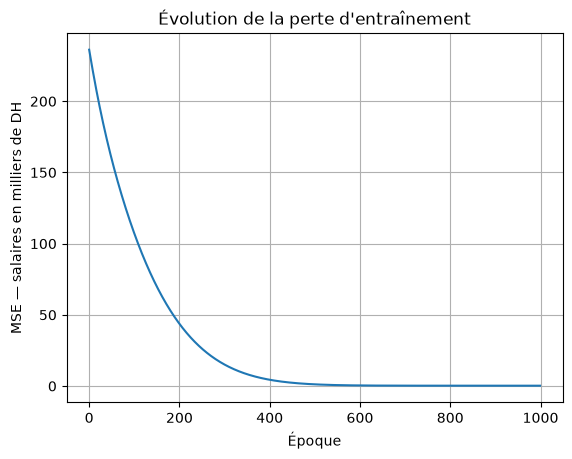

In [106]:
plt.plot(historique)
plt.xlabel("Époque")
plt.ylabel("MSE — salaires en milliers de DH")
plt.title("Évolution de la perte d'entraînement")
plt.grid()
plt.show()

4. Évaluer les prédictions

In [107]:
model.eval()

with torch.no_grad():
    predictions_test = model(X_test_norm)

    # Conversion en DH
    predictions_dh = predictions_test * 1000
    salaires_reels_dh = y_test * 1000

    # À compléter
    mae = torch.mean(torch.abs(predictions_dh - salaires_reels_dh))

print(f"Erreur absolue moyenne : {mae.item():.2f} DH")

Erreur absolue moyenne : 382.41 DH


Interprétation : une MAE de 400 DH signifie que les prédictions s’écartent, en moyenne, de 400 DH des salaires réels.

5. Prédire le salaire d’un nouveau salarié

Prédisez le salaire d’une personne ayant :

- 7 ans d’ancienneté ;
- un niveau d’expertise de 4/5.

In [108]:
nouveau_salarie = torch.tensor([[7.0, 4.0]])

# Appliquer la même normalisation qu'à l'entraînement
nouveau_salarie_norm = (nouveau_salarie - moyenne) / ecart_type

with torch.no_grad():
    salaire_predit = model(nouveau_salarie_norm) * 1000

print(f"Salaire estimé : {salaire_predit.item():.2f} DH")

Salaire estimé : 14197.35 DH


Vérification : d’après la règle de génération, le salaire sans bruit est :

4000 + 600 * 7 + 1500 * 4 = 14200 DH

Votre prédiction devrait être proche de cette valeur.

Questions complémentaires :

- À expertise constante, quel est l’effet d’une année d’ancienneté supplémentaire ?
- Pourquoi la perte ne devient-elle pas exactement nulle ?
- Le modèle est-il fiable pour une ancienneté de 40 ans, absente des données d’entraînement ?
- Quel effet aurait une augmentation du bruit sur la précision ?
- Retrouvez les coefficients en unités d’origine à partir des paramètres du modèle entraîné. Ils devraient être proches de 600, 1500 et 4000.

Remarque : traiter l’expertise comme une note numérique suppose que chaque passage d’un niveau au suivant a le même effet sur le salaire. Cette hypothèse simplifie l’exercice, mais doit être vérifiée avec des données réelles.

**Retrouver les coefficients en unités d'origine**

Le modèle a été entraîné sur des entrées standardisées $x' = (x - \mu) / \sigma$ et une sortie en milliers de DH :

$$\hat y_{k} = \sum_j w'_j \frac{x_j - \mu_j}{\sigma_j} + b'$$

En développant, on obtient en DH :

$$w_j = 1000 \cdot \frac{w'_j}{\sigma_j}, \qquad b = 1000 \cdot \Big(b' - \sum_j \frac{w'_j \mu_j}{\sigma_j}\Big)$$

In [109]:
w_norm = model.weight.detach().squeeze()    # (2,)
b_norm = model.bias.detach().item()
mu = moyenne.squeeze()
sigma = ecart_type.squeeze()

w_orig = 1000 * w_norm / sigma
b_orig = 1000 * (b_norm - (w_norm * mu / sigma).sum().item())

print(f"w1 (ancienneté) ≈ {w_orig[0].item():8.2f} DH / an      (attendu 600)")
print(f"w2 (expertise)  ≈ {w_orig[1].item():8.2f} DH / niveau  (attendu 1500)")
print(f"b  (constante)  ≈ {b_orig:8.2f} DH            (attendu 4000)")

w1 (ancienneté) ≈   592.66 DH / an      (attendu 600)
w2 (expertise)  ≈  1490.75 DH / niveau  (attendu 1500)
b  (constante)  ≈  4085.71 DH            (attendu 4000)


In [110]:
# Extrapolation : ancienneté de 40 ans (hors du domaine 0–20 ans vu à l'entraînement)
cas_40 = (torch.tensor([[40.0, 4.0]]) - moyenne) / ecart_type
with torch.no_grad():
    print(f"Salaire prédit pour 40 ans / expertise 4 : {model(cas_40).item() * 1000:.2f} DH")
print(f"Règle de génération                      : {4000 + 600 * 40 + 1500 * 4:.2f} DH")

Salaire prédit pour 40 ans / expertise 4 : 33755.27 DH
Règle de génération                      : 34000.00 DH


In [111]:
# Effet du bruit : on régénère les salaires avec différents niveaux de bruit
def entrainer_et_evaluer(niveau_bruit, epochs=1000):
    torch.manual_seed(0)
    y_b = 4000 + 600 * anciennete + 1500 * expertise + torch.randn(n, 1) * niveau_bruit
    y_tr, y_te = y_b[train_indices] / 1000, y_b[test_indices] / 1000

    m = nn.Linear(2, 1)
    opt = torch.optim.Adam(m.parameters(), lr=0.05)
    for _ in range(epochs):
        opt.zero_grad()
        perte = nn.functional.mse_loss(m(X_train_norm), y_tr)
        perte.backward()
        opt.step()

    with torch.no_grad():
        mae_b = (m(X_test_norm) - y_te).abs().mean().item() * 1000
    return perte.item(), mae_b

for niveau_bruit in [0, 250, 500, 1000, 2000]:
    perte_finale, mae_b = entrainer_et_evaluer(niveau_bruit)
    print(f"bruit σ = {niveau_bruit:5d} DH | MSE train = {perte_finale:7.4f} | MAE test = {mae_b:8.2f} DH")

bruit σ =     0 DH | MSE train =  0.0000 | MAE test =     3.52 DH
bruit σ =   250 DH | MSE train =  0.0561 | MAE test =   168.61 DH
bruit σ =   500 DH | MSE train =  0.2244 | MAE test =   337.80 DH
bruit σ =  1000 DH | MSE train =  0.8975 | MAE test =   676.19 DH
bruit σ =  2000 DH | MSE train =  3.5899 | MAE test =  1352.96 DH


**Réponses aux questions complémentaires**

1. **Effet d'une année d'ancienneté supplémentaire (à expertise constante) :** le salaire augmente de $w_1$, soit environ **+600 DH par mois** (voir les coefficients retrouvés ci‑dessus). C'est l'interprétation d'un coefficient de régression linéaire multiple : effet marginal d'une variable, toutes les autres étant fixées.

2. **Pourquoi la perte ne devient pas nulle :** les salaires contiennent un bruit aléatoire ($\sigma = 500$ DH) que l'ancienneté et l'expertise ne peuvent pas expliquer. Même avec les vrais coefficients, l'erreur restante est ce bruit : la MSE plancher vaut environ $\sigma^2 = 500^2$ DH², soit **≈ 0,25** en milliers de DH², ce qui correspond à la valeur où la courbe de perte se stabilise. C'est une erreur *irréductible*, pas un défaut d'optimisation.

3. **Fiabilité pour 40 ans d'ancienneté :** non, il s'agit d'une **extrapolation** hors du domaine observé (0 à 20 ans). Ici la prédiction reste cohérente uniquement parce que les données ont été générées par une règle parfaitement linéaire. Sur des données réelles, rien ne garantit que la relation reste linéaire au‑delà de 20 ans (plafonnement des grilles, changement de poste, départ à la retraite…), donc la prédiction ne serait pas fiable.

4. **Effet d'une augmentation du bruit :** l'expérience ci‑dessus montre que la MAE de test et la perte plancher augmentent avec le bruit (la MSE croît comme $\sigma^2$, la MAE environ comme $0{,}8\,\sigma$). Les coefficients appris deviennent aussi moins précis, car le modèle dispose de moins d'information « propre » pour les estimer.

5. **Coefficients en unités d'origine :** voir la cellule de conversion ci‑dessus ; on retrouve des valeurs proches de **600**, **1500** et **4000**.

###  Exercice 3  — Classification des fleurs Iris 🌸

Objectif : entraîner un réseau de neurones pour prédire l’espèce d’une fleur à partir de quatre mesures :

- longueur et largeur des sépales ;
- longueur et largeur des pétales.

Le jeu de données Iris contient 150 fleurs réparties en trois classes : setosa, versicolor et virginica.


Bibliothèques : torch, scikit-learn.

**1. Préparation des données**

In [112]:
import torch
from torch import nn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)

# Charger les données
iris = load_iris()
X, y = iris.data, iris.target

# Séparer les données : 80 % entraînement, 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Ajuster la normalisation uniquement sur l'entraînement
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convertir en tenseurs
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Dimensions :", X_train.shape, y_train.shape)

Dimensions : torch.Size([120, 4]) torch.Size([120])


**Questions :**

- Que représentent les quatre colonnes de X_train ?
- Pourquoi utilise-t-on torch.long pour les étiquettes ?
- Pourquoi ne faut-il pas ajuster le StandardScaler sur les données de test ?

**Réponses :**

- **Les quatre colonnes de `X_train`** sont les mesures de chaque fleur, en cm : longueur du sépale, largeur du sépale, longueur du pétale, largeur du pétale (`iris.feature_names`). Après le `StandardScaler`, elles sont centrées‑réduites (moyenne 0, écart‑type 1 sur le jeu d'entraînement).
- **`torch.long` pour les étiquettes :** `nn.CrossEntropyLoss` attend des **indices de classe entiers** (0, 1 ou 2) de type `int64`, qu'elle utilise pour sélectionner le logit de la bonne classe. Ce ne sont pas des valeurs continues à approcher, donc un type flottant provoquerait une erreur (ou serait interprété comme des probabilités).
- **Ne pas ajuster le scaler sur le test :** le jeu de test simule des données jamais vues. Calculer la moyenne et l'écart‑type sur le test ferait **fuiter de l'information** (data leakage) vers le prétraitement et donnerait une évaluation trop optimiste. En production, on ne connaît pas à l'avance les statistiques des futures données : on applique celles apprises à l'entraînement (`transform` seulement).

**2. Construire le réseau**

In [113]:
model = nn.Sequential(
    nn.Linear(4, 12),
    nn.ReLU(),
    nn.Linear(12, 3)   # 3 classes : setosa, versicolor, virginica
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

Attention : n’ajoutez pas de Softmax à la sortie. CrossEntropyLoss attend directement les scores bruts, appelés logits.

**3. Entraîner le modèle**

Complétez la boucle d’entraînement. Pour cet exercice, chaque itération utilise toutes les données d’entraînement.

In [114]:
epochs = 200
losses = []

model.train()

for epoch in range(epochs):
    # 1. Réinitialiser les gradients
    optimizer.zero_grad()

    # 2. Calculer les scores prédits (logits)
    logits = model(X_train)

    # 3. Calculer la perte
    loss = criterion(logits, y_train)

    # 4. Calculer les gradients
    loss.backward()

    # 5. Mettre à jour les paramètres
    optimizer.step()

    losses.append(loss.item())

    if (epoch + 1) % 20 == 0:
        print(f"Époque {epoch + 1:3d} | Perte : {loss.item():.4f}")

Époque  20 | Perte : 0.5355
Époque  40 | Perte : 0.2787
Époque  60 | Perte : 0.1549
Époque  80 | Perte : 0.0957
Époque 100 | Perte : 0.0709
Époque 120 | Perte : 0.0593
Époque 140 | Perte : 0.0528
Époque 160 | Perte : 0.0485
Époque 180 | Perte : 0.0455
Époque 200 | Perte : 0.0432


**4. Évaluer le classifieur**

Complétez le calcul des prédictions et de l’accuracy, c’est-à-dire la proportion de fleurs correctement classées.

In [115]:
model.eval()

with torch.no_grad():
    logits = model(X_test)

    # TODO : sélectionner la classe au score maximal pour chaque fleur
    predictions = logits.argmax(dim=1)

    # TODO : calculer la proportion de prédictions correctes
    accuracy = (predictions == y_test).float().mean()

print(f"Accuracy sur le test : {accuracy.item():.1%}")

Accuracy sur le test : 96.7%


**5- Autres question :**

- Tracez la courbe de perte.
- Affichez une matrice de confusion.
- Comparez ce réseau à un modèle sans couche cachée : nn.Linear(4, 3).
- Prédisez l’espèce d’une nouvelle fleur de mesures [5.1, 3.5, 1.4, 0.2], après l’avoir normalisée avec le même scaler.

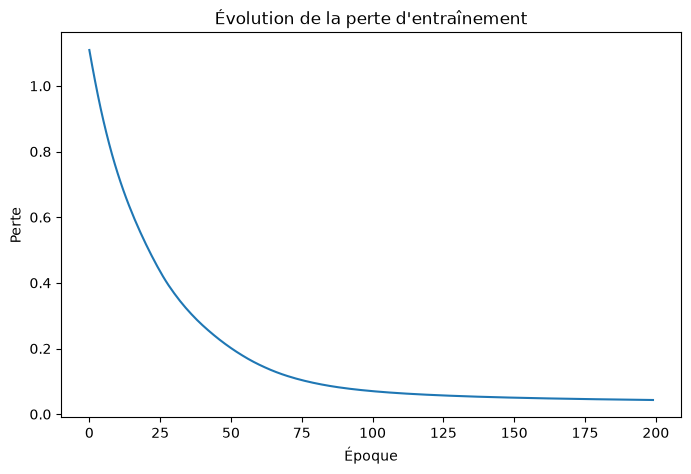

In [116]:
#Tracez la courbe de perte.
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(losses)
plt.title("Évolution de la perte d'entraînement")
plt.xlabel("Époque")
plt.ylabel("Perte")
plt.show()

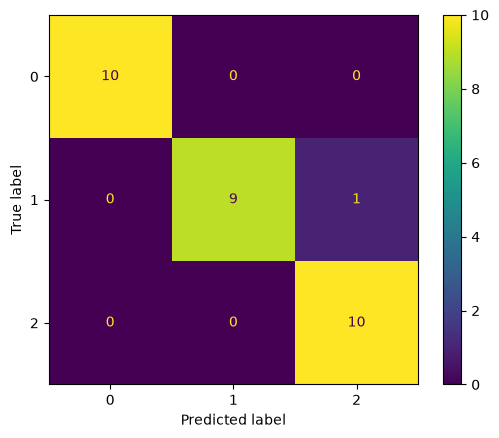

In [117]:
#- Affichez une matrice de confusion.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

MLP (4→12→3)      :  99 paramètres | perte finale = 0.0432 | accuracy test = 96.7%
Linéaire (4→3)    :  15 paramètres | perte finale = 0.2416 | accuracy test = 90.0%


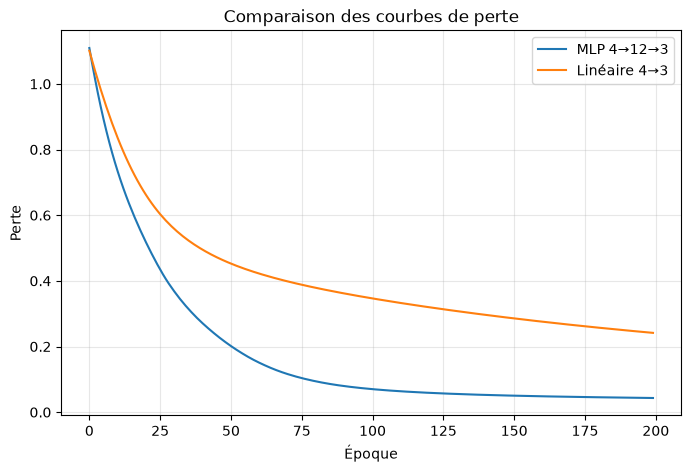

In [118]:
# Comparaison avec un modèle sans couche cachée : nn.Linear(4, 3)
torch.manual_seed(42)
model_lineaire = nn.Linear(4, 3)
optimizer_lin = torch.optim.Adam(model_lineaire.parameters(), lr=0.01)

losses_lin = []
model_lineaire.train()
for epoch in range(epochs):
    optimizer_lin.zero_grad()
    loss_lin = criterion(model_lineaire(X_train), y_train)
    loss_lin.backward()
    optimizer_lin.step()
    losses_lin.append(loss_lin.item())

model_lineaire.eval()
with torch.no_grad():
    acc_lin = (model_lineaire(X_test).argmax(dim=1) == y_test).float().mean().item()

n_params_mlp = sum(p.numel() for p in model.parameters())
n_params_lin = sum(p.numel() for p in model_lineaire.parameters())

print(f"MLP (4→12→3)      : {n_params_mlp:3d} paramètres | perte finale = {losses[-1]:.4f} | accuracy test = {accuracy.item():.1%}")
print(f"Linéaire (4→3)    : {n_params_lin:3d} paramètres | perte finale = {losses_lin[-1]:.4f} | accuracy test = {acc_lin:.1%}")

plt.figure(figsize=(8, 5))
plt.plot(losses, label="MLP 4→12→3")
plt.plot(losses_lin, label="Linéaire 4→3")
plt.xlabel("Époque")
plt.ylabel("Perte")
plt.title("Comparaison des courbes de perte")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Conclusion de la comparaison :** le réseau avec couche cachée converge plus vite et atteint une perte d'entraînement plus basse, car la ReLU lui permet d'apprendre des frontières de décision **non linéaires**. Le modèle linéaire (régression logistique multinomiale) ne trace que des frontières linéaires. Sur Iris, les deux modèles obtiennent cependant une accuracy de test proche : setosa est parfaitement séparable, et versicolor / virginica le sont presque linéairement. Avec 30 fleurs de test, une seule erreur fait varier l'accuracy de 3,3 points, donc l'écart n'est pas significatif. La couche cachée apporte surtout un gain sur des problèmes plus complexes, avec le risque de sur‑apprentissage que cela implique.

In [119]:
# Prédire l'espèce d'une nouvelle fleur
nouvelle_fleur = [[5.1, 3.5, 1.4, 0.2]]

# Même normalisation que pour l'entraînement (transform, pas fit_transform)
nouvelle_fleur_norm = torch.tensor(scaler.transform(nouvelle_fleur), dtype=torch.float32)

model.eval()
with torch.no_grad():
    logits_fleur = model(nouvelle_fleur_norm)
    probas = torch.softmax(logits_fleur, dim=1).squeeze()   # softmax uniquement pour l'affichage
    classe = logits_fleur.argmax(dim=1).item()

print("Espèce prédite :", iris.target_names[classe])
for nom, p in zip(iris.target_names, probas):
    print(f"  {nom:<11s}: {p.item():.1%}")

Espèce prédite : setosa
  setosa     : 99.9%
  versicolor : 0.1%
  virginica  : 0.0%


### Exercice 2 : Classifier les chiffres MNIST
Objectif : utiliser des mini-lots et évaluer un modèle sur des données de test.

Chargement des données

In [120]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False
)

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

#### Travail demandé : 
- Entraînez le modèle pendant 5 époques.
- Utilisez model.train() pendant l’entraînement.
- Évaluez-le avec model.eval() et torch.no_grad().
- Obtenez les classes prédites avec :
   - predicted_classes = outputs.argmax(dim=1)
   - Calculez mes métriques Accuracy, Recall, Precision et f1-Score sur le jeu de test.
   - Afficher la matrice de confusion
   - Affichez quelques images mal classées.
- Sauvegarder et recharger un modèle : réutiliser un réseau entraîné sans recommencer l’apprentissage.

Attention : CrossEntropyLoss attend les sorties brutes du réseau, sans Softmax, et des étiquettes entières.

**Entraînement (5 époques, mini‑lots de 64 images)**

In [121]:
epochs = 5
loss_history_mlp = []

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    average_loss = total_loss / len(train_dataset)
    loss_history_mlp.append(average_loss)
    print(f"Époque {epoch + 1}/{epochs} | Perte : {average_loss:.4f}")

Époque 1/5 | Perte : 0.3430
Époque 2/5 | Perte : 0.1534
Époque 3/5 | Perte : 0.1055
Époque 4/5 | Perte : 0.0798
Époque 5/5 | Perte : 0.0628


**Évaluation sur le jeu de test**

In [122]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

model.eval()

all_preds, all_labels, all_images = [], [], []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predicted_classes = outputs.argmax(dim=1)

        all_preds.append(predicted_classes)
        all_labels.append(labels)
        all_images.append(images)

all_preds = torch.cat(all_preds)
all_labels = torch.cat(all_labels)
all_images = torch.cat(all_images)

# Moyenne « macro » : chaque chiffre compte autant dans la moyenne
acc = accuracy_score(all_labels, all_preds)
rec = recall_score(all_labels, all_preds, average="macro")
prec = precision_score(all_labels, all_preds, average="macro")
f1 = f1_score(all_labels, all_preds, average="macro")

print(f"Accuracy  : {acc:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"Precision : {prec:.4f}")
print(f"F1-score  : {f1:.4f}")
print()
print(classification_report(all_labels, all_preds, digits=4))

Accuracy  : 0.9740
Recall    : 0.9736
Precision : 0.9743
F1-score  : 0.9738

              precision    recall  f1-score   support

           0     0.9769    0.9918    0.9843       980
           1     0.9783    0.9912    0.9847      1135
           2     0.9693    0.9797    0.9745      1032
           3     0.9619    0.9743    0.9680      1010
           4     0.9796    0.9766    0.9781       982
           5     0.9930    0.9507    0.9714       892
           6     0.9751    0.9823    0.9787       958
           7     0.9747    0.9728    0.9737      1028
           8     0.9451    0.9713    0.9580       974
           9     0.9896    0.9455    0.9671      1009

    accuracy                         0.9740     10000
   macro avg     0.9743    0.9736    0.9738     10000
weighted avg     0.9742    0.9740    0.9740     10000



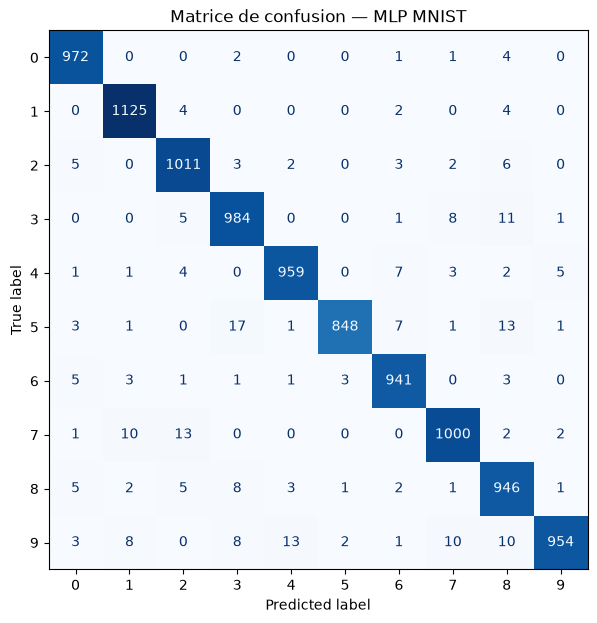

In [123]:
# Matrice de confusion
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(all_labels, all_preds, ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matrice de confusion — MLP MNIST")
plt.show()

Nombre d'images mal classées : 260 / 10000


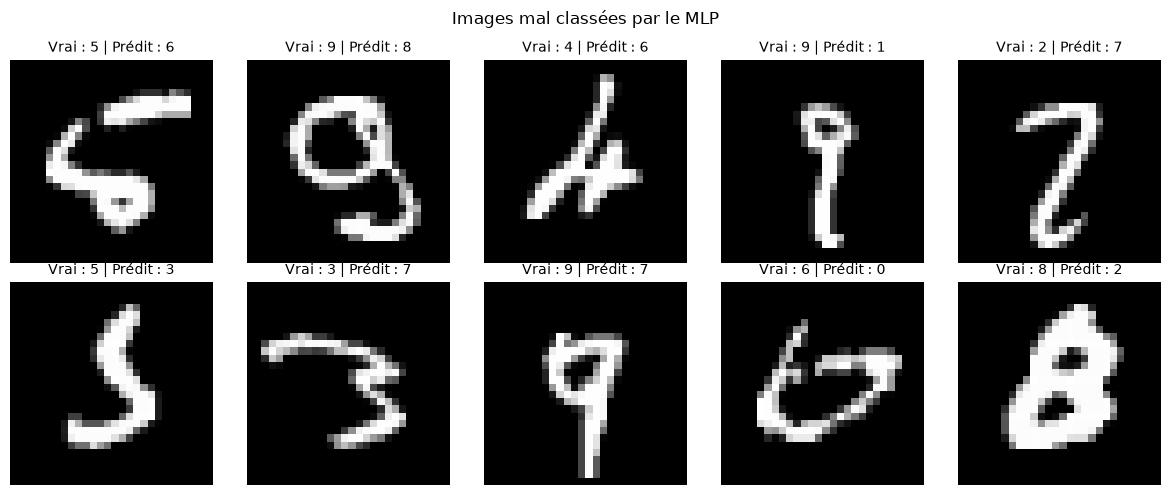

In [124]:
# Quelques images mal classées
erreurs = (all_preds != all_labels).nonzero().squeeze()
print(f"Nombre d'images mal classées : {len(erreurs)} / {len(all_labels)}")

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, idx in zip(axes.flat, erreurs[:10]):
    ax.imshow(all_images[idx, 0], cmap="gray")
    ax.set_title(f"Vrai : {all_labels[idx].item()} | Prédit : {all_preds[idx].item()}", fontsize=10)
    ax.axis("off")
plt.suptitle("Images mal classées par le MLP")
plt.tight_layout()
plt.show()

**Sauvegarder et recharger le modèle**

In [125]:
chemin = "mnist_mlp.pth"
torch.save(model.state_dict(), chemin)
print("Modèle sauvegardé dans", chemin)

# Recréer la même architecture, puis charger les paramètres (sans réentraîner)
model_recharge = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)
model_recharge.load_state_dict(torch.load(chemin, weights_only=True))
model_recharge.eval()

with torch.no_grad():
    preds_recharge = torch.cat([model_recharge(images).argmax(dim=1) for images, _ in test_loader])

print("Prédictions identiques :", torch.equal(preds_recharge, all_preds))
print(f"Accuracy du modèle rechargé : {(preds_recharge == all_labels).float().mean().item():.4f}")

Modèle sauvegardé dans mnist_mlp.pth
Prédictions identiques : True
Accuracy du modèle rechargé : 0.9740


### Exercice 4 — Classification MNIST avec un CNN

Objectif : construire un réseau de neurones convolutif (CNN) pour reconnaître les chiffres manuscrits de 0 à 9.

MNIST contient 60 000 images d’entraînement et 10 000 images de test, en niveaux de gris, de taille 28 × 28 pixels.

**1. Chargement des données**

In [126]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)

test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False
)

images, labels = next(iter(train_loader))

print("Images :", images.shape)  # [64, 1, 28, 28]
print("Labels :", labels.shape)  # [64]

Appareil : cpu
Images : torch.Size([64, 1, 28, 28])
Labels : torch.Size([64])


**Questions :**

- Que représentent les quatre dimensions du tenseur images ?
- Pourquoi mélanger les données d’entraînement avec shuffle=True ?

**Réponses :**

- **Les quatre dimensions de `images` `[64, 1, 28, 28]`** sont, dans l'ordre : la taille du mini‑lot (64 images), le nombre de canaux (1, car les images sont en niveaux de gris ; ce serait 3 en RGB), la hauteur (28 pixels) et la largeur (28 pixels). C'est le format `[N, C, H, W]` attendu par `nn.Conv2d`.
- **Pourquoi `shuffle=True` :** mélanger les données à chaque époque évite que les mini‑lots soient toujours composés des mêmes exemples dans le même ordre (par exemple, des lots ne contenant qu'un seul chiffre si les données étaient triées). Les gradients de chaque lot sont ainsi plus représentatifs de l'ensemble, ce qui stabilise la descente de gradient stochastique et limite le sur‑apprentissage lié à l'ordre. On ne mélange pas le test car l'ordre n'a aucune influence sur l'évaluation.

**2. Visualiser quelques images**

Complétez l’affichage des étiquettes :

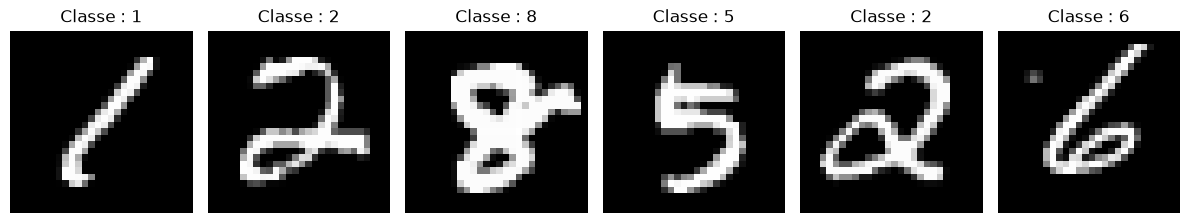

In [127]:
fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, ax in enumerate(axes):
    # Annuler la normalisation pour l'affichage
    image = images[i, 0] * 0.3081 + 0.1307

    ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Classe : {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

**3. Construire le CNN**

Implémentez cette architecture :

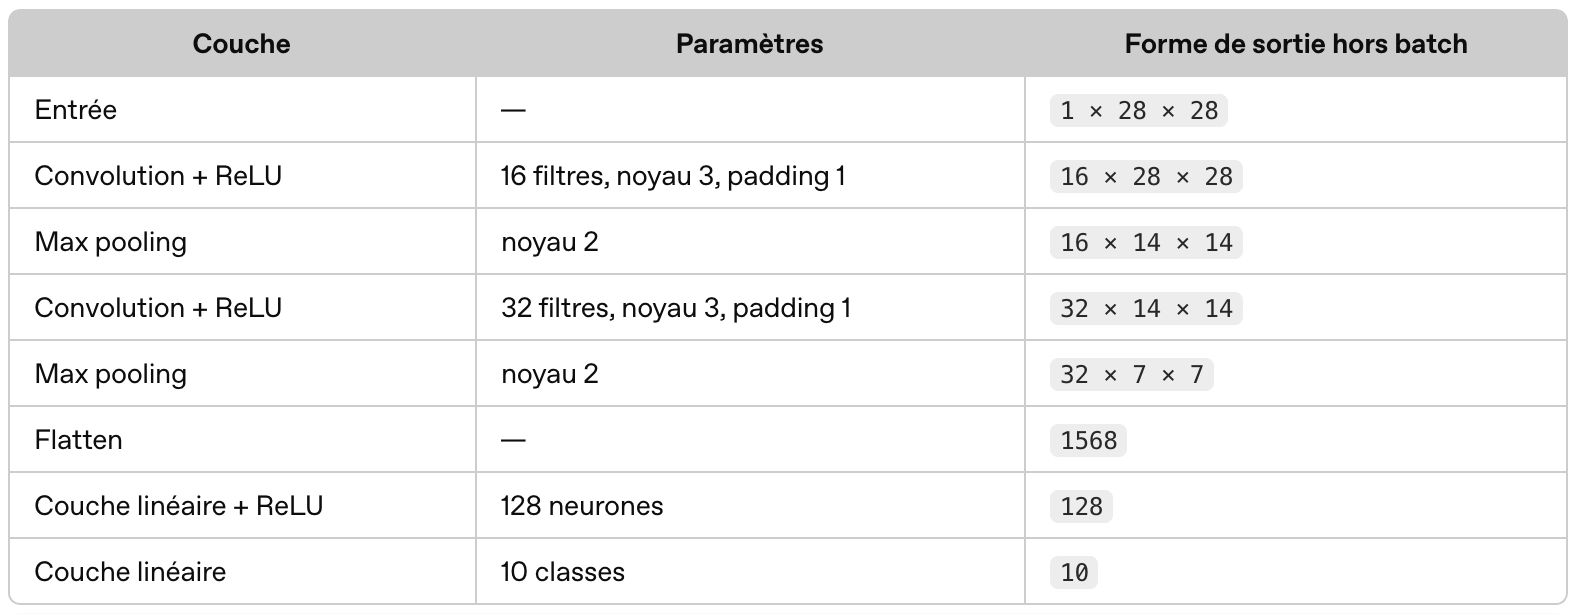

In [128]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(
                in_channels=1,      # image en niveaux de gris
                out_channels=16,    # 16 filtres
                kernel_size=3,
                padding=1
            ),                      # -> 16 x 28 x 28
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),   # -> 16 x 14 x 14

            nn.Conv2d(
                in_channels=16,
                out_channels=32,    # 32 filtres
                kernel_size=3,
                padding=1
            ),                      # -> 32 x 14 x 14
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)    # -> 32 x 7 x 7
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),                  # -> 1568
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)             # 10 classes (logits)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = MNISTClassifier().to(device)

# Vérifier la forme de sortie
with torch.no_grad():
    output = model(images.to(device))

assert output.shape == (images.size(0), 10)
print("Sortie :", output.shape)

Sortie : torch.Size([64, 10])


**Question :** pourquoi la première couche linéaire reçoit-elle 32 × 7 × 7 valeurs ?

Attention : n’ajoutez pas de Softmax au modèle. CrossEntropyLoss attend les scores bruts, appelés logits.

**Réponse :** chaque bloc *convolution + max pooling* conserve la taille spatiale lors de la convolution (noyau 3 avec `padding=1`) puis la divise par 2 avec le pooling : $28 \to 14 \to 7$. Après la deuxième convolution, il y a **32 cartes de caractéristiques** (une par filtre) de taille **7 × 7**. `nn.Flatten()` met ce tenseur `[N, 32, 7, 7]` à plat en un vecteur de $32 \times 7 \times 7 = 1568$ valeurs par image, qui est donc la taille d'entrée de la première couche linéaire.

**4. Entraîner le réseau**

In [129]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 3
loss_history = []

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # 1. Réinitialiser les gradients
        optimizer.zero_grad()

        # 2. Calculer les scores
        logits = model(images)

        # 3. Calculer la perte
        loss = criterion(logits, labels)

        # 4. Calculer les gradients
        loss.backward()

        # 5. Mettre à jour les paramètres
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    average_loss = total_loss / len(train_dataset)
    loss_history.append(average_loss)

    print(
        f"Époque {epoch + 1}/{epochs} "
        f"| Perte : {average_loss:.4f}"
    )

Époque 1/3 | Perte : 0.1680
Époque 2/3 | Perte : 0.0482
Époque 3/3 | Perte : 0.0348


**5. Évaluer sur le jeu de test**

In [130]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)

        # Classe ayant le score le plus élevé
        predictions = logits.argmax(dim=1)

        # Compter les bonnes prédictions
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = correct / total
print(f"Accuracy sur le test : {accuracy:.2%}")

Accuracy sur le test : 98.91%


**Indices :**

- argmax(dim=1) sélectionne une classe pour chaque image ;
(predictions == labels).sum().item() compte les prédictions correctes.

- Résultat attendu : une accuracy généralement supérieure à 97 % après quelques époques, sans garantie exacte.

**Autres questions :**

- Affichez 10 images mal classées, avec leur vraie classe et la prédiction.
- Ajoutez une couche Dropout avant la dernière couche linéaire.
- Sauvegardez les paramètres avec torch.save(model.state_dict(), "mnist_cnn.pth").

**a) 10 images mal classées**

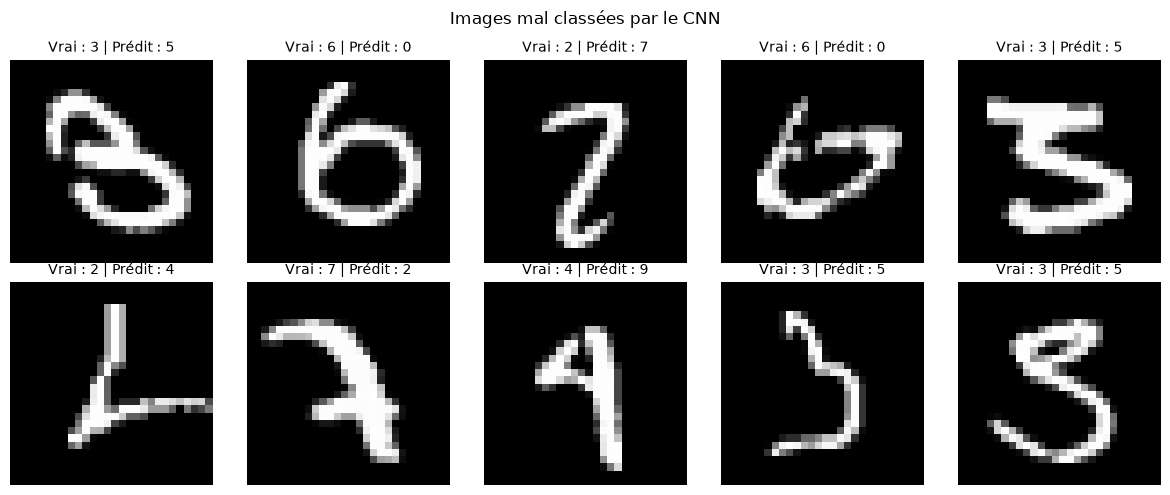

In [131]:
model.eval()

mal_classees = []   # (image, vraie classe, prédiction)

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        predictions = model(images).argmax(dim=1)

        erreurs = (predictions != labels).nonzero().squeeze(1)
        for idx in erreurs:
            mal_classees.append((images[idx].cpu(), labels[idx].item(), predictions[idx].item()))

        if len(mal_classees) >= 10:
            break

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, (image, vrai, predit) in zip(axes.flat, mal_classees[:10]):
    ax.imshow(image[0] * 0.3081 + 0.1307, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Vrai : {vrai} | Prédit : {predit}", fontsize=10)
    ax.axis("off")
plt.suptitle("Images mal classées par le CNN")
plt.tight_layout()
plt.show()

**b) Ajouter une couche Dropout avant la dernière couche linéaire**

Le `Dropout` met aléatoirement à zéro une proportion `p` des activations pendant l'entraînement (`model.train()`), ce qui limite la co‑adaptation des neurones et réduit le sur‑apprentissage. En `model.eval()`, il est désactivé.

In [132]:
class MNISTClassifierDropout(nn.Module):
    def __init__(self, p=0.5):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p=p),          # Dropout avant la dernière couche linéaire
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def evaluer(modele, loader):
    modele.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            correct += (modele(images).argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return correct / total


torch.manual_seed(42)
model_dropout = MNISTClassifierDropout().to(device)
print(model_dropout)

optimizer_dropout = torch.optim.Adam(model_dropout.parameters(), lr=0.001)

for epoch in range(epochs):
    model_dropout.train()
    total_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer_dropout.zero_grad()
        loss = criterion(model_dropout(images), labels)
        loss.backward()
        optimizer_dropout.step()

        total_loss += loss.item() * images.size(0)

    print(f"Époque {epoch + 1}/{epochs} | Perte : {total_loss / len(train_dataset):.4f}")

acc_dropout = evaluer(model_dropout, test_loader)
print(f"\nAccuracy test — CNN sans Dropout : {accuracy:.2%}")
print(f"Accuracy test — CNN avec Dropout : {acc_dropout:.2%}")

MNISTClassifierDropout(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Époque 1/3 | Perte : 0.2488
Époque 2/3 | Perte : 0.0871
Époque 3/3 | Perte : 0.0689

Accuracy test — CNN sans Dropout : 98.91%
Accuracy test — CNN avec Dropout : 98.84%


*Remarque :* avec seulement 3 époques, l'écart d'accuracy entre les deux CNN est faible (de l'ordre de quelques dixièmes de point, dans un sens ou dans l'autre selon l'initialisation). La perte d'entraînement est un peu plus élevée avec le Dropout, car le réseau est volontairement perturbé pendant l'apprentissage. Son intérêt apparaît surtout sur des entraînements plus longs, où il retarde le sur‑apprentissage.

**c) Sauvegarder les paramètres et recharger le modèle**

In [133]:
torch.save(model.state_dict(), "mnist_cnn.pth")
print("Paramètres sauvegardés dans mnist_cnn.pth")

# Recharger dans un nouveau modèle de même architecture, sans réentraîner
model_charge = MNISTClassifier().to(device)
model_charge.load_state_dict(torch.load("mnist_cnn.pth", map_location=device, weights_only=True))
model_charge.eval()

print(f"Accuracy du modèle rechargé : {evaluer(model_charge, test_loader):.2%}")

Paramètres sauvegardés dans mnist_cnn.pth
Accuracy du modèle rechargé : 98.91%
